<a href="https://colab.research.google.com/github/anordonezc/Lab-Calculo-D/blob/main/L2_sesion2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Guía L2 — El índice sancocho · **Sesión 2: el índice en el tiempo y el duelo de ciudades**

**Cálculo Diferencial — Laboratorio computacional** · Universidad Nacional de Colombia, Sede Manizales

Hoy la olla se pone histórica: años de precios oficiales, los picos con nombre propio, el duelo de ciudades, la apuesta de conmutatividad y la unidad monetaria más seria jamás inventada: **el sancocho**.

**Antes de ejecutar:** predicciones P4 y P5 de la guía, en papel, foto al informe. P5 es la apuesta central del laboratorio — no se la salten, que sin apuesta no hay gloria.

In [139]:
import pandas as pd
import matplotlib.pyplot as plt

RUTA = "https://raw.githubusercontent.com/cmorregof/labs-calculo-2026-2/main/datos/sipsa_mensual.csv.gz"
df = pd.read_csv(RUTA)

# La receta oficial y el pipeline de la sesión 1 (los reconstruimos aquí para
# que este cuaderno sea autónomo — reproducibilidad ante todo):
RECETA1 = {
    "Carne de cerdo, espinazo":       1.5,
    "Yuca ICA":                       1.0,
    "Papa capira":                    1.0,
    "Chócolo mazorca":                0.9,
    "Plátano dominico hartón verde":  1.4,
}

def indice_plato(tabla, ciudad, receta):
    "tabla -> serie: costo del plato mes a mes en una ciudad. El pipeline entero, empacado."
    # Si hay varias centrales en la ciudad, se usa su promedio simple por producto y mes.
    t = tabla[(tabla["ciudad"] == ciudad) & (tabla["producto"].isin(receta))]
    p = t.pivot_table(index="fecha", columns="producto", values="precio_kg", aggfunc="mean")
    faltantes = [producto for producto in receta if producto not in p.columns]
    if faltantes:
        raise ValueError(f"{ciudad}: faltan ingredientes de la receta: {faltantes}")
    p = p[list(receta)]
    meses_incompletos = p.index[p.isna().any(axis=1)].to_list()
    if meses_incompletos:
        raise ValueError(f"{ciudad}: receta incompleta en {len(meses_incompletos)} meses; primero revisen la sustitución.")
    return p.mul(pd.Series(receta), axis="columns").sum(axis=1)

print("Pipeline listo. Fíjense: indice_plato RECIBE la tabla, la ciudad y la receta.",
      "Nada global. Cambiar de plato será cambiar un diccionario.")

Pipeline listo. Fíjense: indice_plato RECIBE la tabla, la ciudad y la receta. Nada global. Cambiar de plato será cambiar un diccionario.


## **Ejecutar esta celda si se quiere probar el codigo con el tamal**

In [140]:
df = pd.read_csv(RUTA)

# La receta oficial y el pipeline de la sesión 1 (los reconstruimos aquí para
# que este cuaderno sea autónomo — reproducibilidad ante todo):
RECETA2 = {
    "Rabadillas de pollo":            0.07,
    "Carne de cerdo, tocino papada":  0.05,
    "Arveja verde seca importada":    0.03,
    "Arroz de primera":               0.04,
    "Harina de trigo":                0.1,
}


def indice_plato(tabla, ciudad, receta):
    "tabla -> serie: costo del plato mes a mes en una ciudad. El pipeline entero, empacado."
    # Si hay varias centrales en la ciudad, se usa su promedio simple por producto y mes.
    t = tabla[(tabla["ciudad"] == ciudad) & (tabla["producto"].isin(receta))]
    p = t.pivot_table(index="fecha", columns="producto", values="precio_kg", aggfunc="mean")
    faltantes = [producto for producto in receta if producto not in p.columns]
    if faltantes:
        raise ValueError(f"{ciudad}: faltan ingredientes de la receta: {faltantes}")
    p = p[list(receta)]
    meses_incompletos = p.index[p.isna().any(axis=1)].to_list()
    if meses_incompletos:
        raise ValueError(f"{ciudad}: receta incompleta en {len(meses_incompletos)} meses; primero revisen la sustitución.")
    return p.mul(pd.Series(receta), axis="columns").sum(axis=1)

print("Pipeline listo. Fíjense: indice_plato RECIBE la tabla, la ciudad y la receta.",
      "Nada global. Cambiar de plato será cambiar un diccionario.")

Pipeline listo. Fíjense: indice_plato RECIBE la tabla, la ciudad y la receta. Nada global. Cambiar de plato será cambiar un diccionario.


In [158]:
# Para tener una mejor comparacion con el sancocho, usar este diccionario que tiene una cantidad aproximada de consumo familiar de tamales, o bueno. La cantidad de ingredientes que se necesita para hacer Tamales para una Familia
RECETA2 = {
    "Rabadillas de pollo":            0.7,
    "Carne de cerdo, tocino papada":  0.5,
    "Arveja verde seca importada":    0.3,
    "Arroz de primera":               0.4,
    "Harina de trigo":                1.0,
}

---
## 1 · El índice sancocho, 2013 en adelante

Confronten con su P4: ¿la curva que bosquejaron se parece a la real?

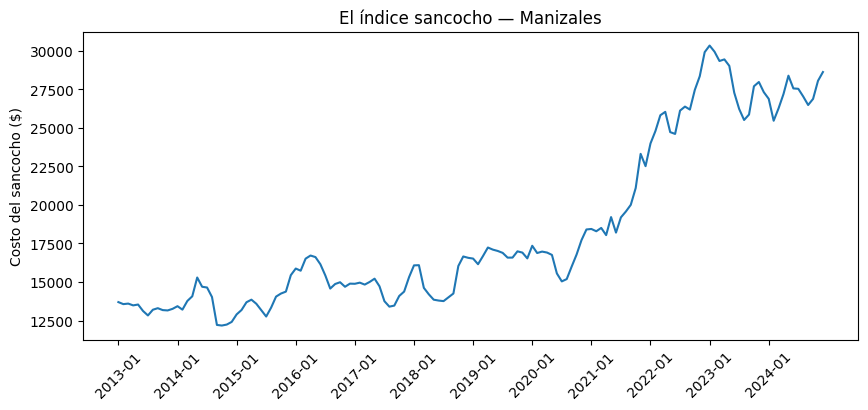

Primer mes (2013-01): $13,695
Último mes (2024-12): $28,634
Variación total: 109.1%


In [156]:
sancocho_mzl = indice_plato(df, "Manizales", RECETA1)

plt.figure(figsize=(10, 4))
plt.plot(range(len(sancocho_mzl)), sancocho_mzl.values)
paso = 12
plt.xticks(range(0, len(sancocho_mzl), paso), sancocho_mzl.index[::paso], rotation=45)
plt.ylabel("Costo del sancocho ($)")
plt.title("El índice sancocho — Manizales")
plt.show()

print(f"Primer mes ({sancocho_mzl.index[0]}): ${sancocho_mzl.iloc[0]:,.0f}")
print(f"Último mes ({sancocho_mzl.index[-1]}): ${sancocho_mzl.iloc[-1]:,.0f}")
print(f"Variación total: {100*(sancocho_mzl.iloc[-1]/sancocho_mzl.iloc[0]-1):.1f}%")

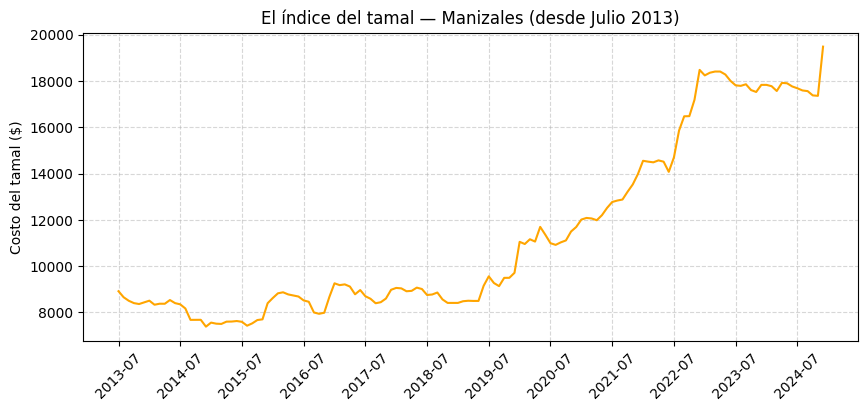

Primer mes (2013-07): $8,915
Último mes (2024-12): $19,481
Variación total: 118.5%


In [159]:



df_filtrado = df[df["fecha"] >= "2013-07"]

# Calculamos el índice con el DataFrame filtrado
tamal_mzl = indice_plato(df_filtrado, "Manizales", RECETA2)

plt.figure(figsize=(10, 4))
plt.plot(range(len(tamal_mzl)), tamal_mzl.values, color='orange')
paso = 12
plt.xticks(range(0, len(tamal_mzl), paso), tamal_mzl.index[::paso], rotation=45)
plt.ylabel("Costo del tamal ($)")
plt.title("El índice del tamal — Manizales (desde Julio 2013)")
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

print(f"Primer mes ({tamal_mzl.index[0]}): ${tamal_mzl.iloc[0]:,.0f}")
print(f"Último mes ({tamal_mzl.index[-1]}): ${tamal_mzl.iloc[-1]:,.0f}")
print(f"Variación total: {100*(tamal_mzl.iloc[-1]/tamal_mzl.iloc[0]-1):.1f}%")

## **Para Poder Evaluarlo con el tamal, tuvimos que cambiar productos y las fechas de las cuales tomabamos la informacion, ya que algunos productos no tenian registros desde fechas anteriores a 2013-8**

🗣️ **Los picos tienen nombre.** Elijan los **dos** saltos más bruscos de la curva. Para cada uno: ¿en qué mes ocurre?, ¿qué pasó en Colombia por esas fechas? (Pistas de historiador: paros, fenómenos de El Niño o La Niña, cosechas, tasa de cambio. Busquen — con IA si quieren, documentando — y sustenten: hipótesis + evidencia, tres líneas por pico.)

*2015–2016: Ocurrió a finales de año con uno de los Fenómenos de El Niño más severos en la historia reciente de Colombia (sequías intensas que dañaron cultivos) golpeando directamente los precios agrícolas. A esto se sumó el gran Paro Nacional Camionero de 2016 (que duró 45 días), bloqueando la comida en los centros de acopio.*

*2021–2022: El disparo del precio de los alimentos durante este periodo se debió al Paro Nacional de mayo 2021 con bloqueos de vías, la crisis logística global y de insumos/fertilizantes por la guerra Rusia-Ucrania para 2022.*

 *2022–2023: Ocurrió entre octubre y diciembre de 2022 hasta enero del 2023. Un periodo severo por el Fenómeno de La Niña (inundaciones prolongadas en zonas agrícolas) y la alta inflación general de alimentos en Colombia.*

---
## 2 · El duelo de ciudades (y el problema de la sustitución)

El sancocho "igual" no existe entre ciudades: el conjunto oficial obliga a decidir **equivalencias** de variedades y cortes. Además, cuando hay varias centrales en una ciudad, `indice_plato` usa el promedio simple de sus observaciones disponibles por producto y mes. El cuaderno trae una receta base que funciona los 144 meses; no es una verdad culinaria. Ambas son decisiones de modelación: defiéndanlas.

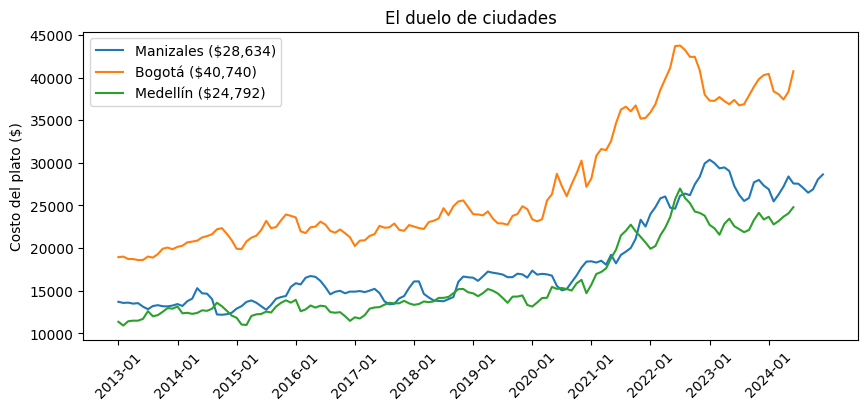

array(['Yuca llanera'], dtype=object)

In [160]:
# ✏️ Ejercicio 1 — Revisen las equivalencias y, si las cambian, defiendan la decisión.
# Pista: df[(df.ciudad=="Bogotá") & (df.producto.str.contains("yuca", case=False))]["producto"].unique()
RECETA_BOGOTA = {
    "Carne de cerdo, costilla":    1.5,   # sustitución del espinazo
    "Yuca llanera":               1.0,
    "Papa parda pastusa":         1.0,
    "Chócolo mazorca":            0.9,
    "Plátano hartón verde":       1.4,
}

RECETA_MEDELLIN = {
    "Carne de cerdo, espinazo":  1.5,
    "Yuca criolla":              1.0,   # sustitución de Yuca ICA
    "Papa capira":               1.0,
    "Chócolo mazorca":           0.9,
    "Plátano hartón verde":      1.4,   # sustitución del dominico hartón
}

series = {
    "Manizales": sancocho_mzl,
    "Bogotá":    indice_plato(df_filtrado, "Bogotá", RECETA_BOGOTA),
    "Medellín":  indice_plato(df_filtrado, "Medellín", RECETA_MEDELLIN),
}

plt.figure(figsize=(10, 4))
for ciudad, s in series.items():
    plt.plot(range(len(s)), s.values, label=f"{ciudad} (${s.iloc[-1]:,.0f})")
plt.xticks(range(0, len(sancocho_mzl), 12), sancocho_mzl.index[::12], rotation=45)
plt.ylabel("Costo del plato ($)")
plt.title("El duelo de ciudades")
plt.legend()
plt.show()

comparacion = pd.DataFrame({
    ciudad: {"inicio": serie.iloc[0], "final": serie.iloc[-1]}
    for ciudad, serie in series.items()
}).T
comparacion["aumento en pesos"] = comparacion["final"] - comparacion["inicio"]
comparacion["aumento porcentual"] = 100 * (comparacion["final"] / comparacion["inicio"] - 1)
comparacion.round({"inicio": 0, "final": 0, "aumento en pesos": 0, "aumento porcentual": 1})
df[(df.ciudad=="Bogotá") & (df.producto.str.contains("yuca", case=False))]["producto"].unique()

In [161]:
# ✏️ Ejercicio 1 — Revisen las equivalencias y, si las cambian, defiendan la decisión.
# Pista: df[(df.ciudad=="Bogotá") & (df.producto.str.contains("yuca", case=False))]["producto"].unique()
RECETA_BOGOTA2 = {
    "Pechuga de pollo":               0.2,
    "Carne de cerdo, tocino papada":  0.15,
    "Arveja verde seca importada":    0.1,
    "Garbanzo importado":             0.15,  # Añadido: marcador tradicional bogotano
    "Arroz de primera":               0.3,   # Se mantiene: el tamal bogotano lleva arroz
    "Harina precocida de maíz":       0.1,   # Ajustado por fidelidad de consistencia
}

RECETA_MEDELLIN2 = {
    "Carne de cerdo, tocino papada":  0.35,  # Se consume mas carne de cerdo, tipico de los paisas
    "Carne de cerdo, costilla":       0.25,  # Añadido: Es tipico de Antioquia
    "Arveja verde seca importada":    0.15,
    "Harina de maíz":       0.25,  # Se aumenta ya que es constumbre en el Tamal Antioqueño
}

series = {
    "Manizales": tamal_mzl,
    "Bogotá":    indice_plato(df_filtrado, "Bogotá", RECETA_BOGOTA2),
    "Medellín":  indice_plato(df_filtrado, "Medellín", RECETA_MEDELLIN2),
}

plt.figure(figsize=(10, 4))
for ciudad, s in series.items():
    plt.plot(range(len(s)), s.values, label=f"{ciudad} (${s.iloc[-1]:,.0f})")
plt.xticks(range(0, len(sancocho_mzl), 12), sancocho_mzl.index[::12], rotation=45)
plt.ylabel("Costo del plato ($)")
plt.title("El duelo de ciudades")
plt.legend()
plt.show()

comparacion = pd.DataFrame({
    ciudad: {"inicio": serie.iloc[0], "final": serie.iloc[-1]}
    for ciudad, serie in series.items()
}).T
comparacion["aumento en pesos"] = comparacion["final"] - comparacion["inicio"]
comparacion["aumento porcentual"] = 100 * (comparacion["final"] / comparacion["inicio"] - 1)
comparacion.round({"inicio": 0, "final": 0, "aumento en pesos": 0, "aumento porcentual": 1})
df[(df.ciudad=="Bogotá") & (df.producto.str.contains("yuca", case=False))]["producto"].unique()

ValueError: Medellín: faltan ingredientes de la receta: ['Harina de maíz']

In [162]:
busca = input("Que nombre exacto deseas buscar: ")
coincidencias = df_filtrado.loc[
    df_filtrado["producto"].str.contains(busca, case=False, na=False),
    ["ciudad", "mercado", "producto"],
]
print(coincidencias["producto"].drop_duplicates().to_list())


Que nombre exacto deseas buscar: hola
[]


In [163]:
# Hecho por IA para comprobar si el producto "harina de maiz" tenia registros en medellin despues de que saltaran varios errores

def auditar_registros_ingrediente(df, ciudad, producto):
    print(f"=== AUDITORÍA PARA: {producto} EN {ciudad.upper()} ===")

    # 1. Filtrar el DataFrame por la ciudad y el producto en cuestión
    df_filtrado_item = df[(df['ciudad'] == ciudad) & (df['producto'] == producto)].copy()

    if df_filtrado_item.empty:
        print(f"❌ ERROR CRÍTICO: El producto '{producto}' no tiene absolutamente ningún registro en {ciudad}.\n")
        return

    # 2. Asegurar que la columna de fecha esté en formato datetime
    df_filtrado_item['fecha'] = pd.to_datetime(df_filtrado_item['fecha'])

    # 3. Agrupar por año y mes para verificar conteo de registros y precios válidos
    df_filtrado_item['Año'] = df_filtrado_item['fecha'].dt.year
    df_filtrado_item['Mes'] = df_filtrado_item['fecha'].dt.month

    resumen_mensual = df_filtrado_item.groupby(['Año', 'Mes']).agg(
        total_registros=('precio', 'count'),
        precios_validos=('precio', lambda x: x.notna().sum())
    ).reset_index()

    # 4. Encontrar meses donde el conteo de precios válidos sea 0 (vacíos temporales)
    meses_sin_datos = resumen_mensual[resumen_mensual['precios_validos'] == 0]

    # 5. Mostrar resultados en consola
    total_historico = len(df_filtrado_item)
    print(f"• Total de filas encontradas en el dataset: {total_historico}")
    print(f"• Meses con reportes activos: {len(resumen_mensual) - len(meses_sin_datos)}")

    if not meses_sin_datos.empty:
        print(f"\n⚠️ SE DETECTARON VACÍOS TEMPORALES ({len(meses_sin_datos)} meses sin precios):")
        for _, fila in meses_sin_datos.iterrows():
            print(f"  - Año: {int(fila['Año'])}, Mes: {int(fila['Mes'])} -> 0 precios registrados.")
    else:
        print("\n✅ Estructura temporal completa: El producto tiene precios reportados en todos los meses registrados.")
    print("=" * 50 + "\n")

# --- EJECUTAR EL DIAGNÓSTICO ---
# Prueba con el nombre original que tenías en mente
auditar_registros_ingrediente(df_filtrado, "Medellín", "Harina de maíz")


=== AUDITORÍA PARA: Harina de maíz EN MEDELLÍN ===
❌ ERROR CRÍTICO: El producto 'Harina de maíz' no tiene absolutamente ningún registro en Medellín.



# ***Usamos como alternativa "Maiz blanco trillado" para que la comparacion sea valida***

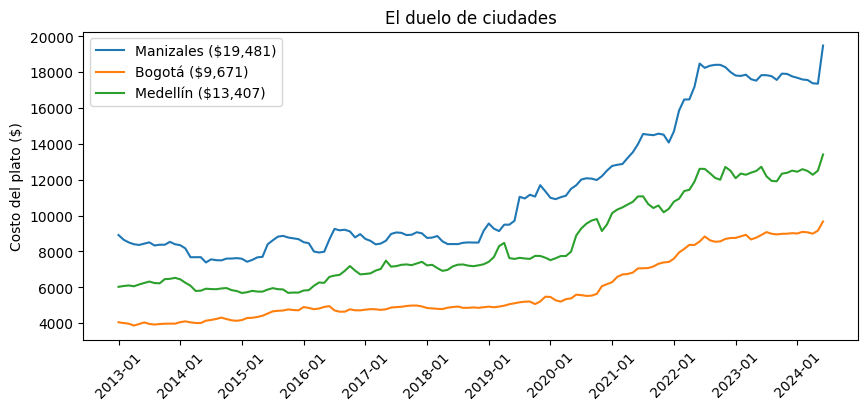

array(['Yuca llanera'], dtype=object)

In [164]:
# Comparacion Fiel con el tamal, con algunos ajustes por falta de informacion en algunos productos
RECETA_BOGOTA2 = {
    "Pechuga de pollo":               0.2,
    "Carne de cerdo, tocino papada":  0.15,
    "Arveja verde seca importada":    0.1,
    "Garbanzo importado":             0.15,  # Añadido: marcador tradicional bogotano
    "Arroz de primera":               0.3,   # Se mantiene: el tamal bogotano lleva arroz
    "Harina precocida de maíz":       0.1,   # Ajustado por fidelidad de consistencia
}

RECETA_MEDELLIN2 = {
    "Carne de cerdo, tocino papada":  0.35,  # Se consume mas carne de cerdo, tipico de los paisas
    "Carne de cerdo, costilla":       0.25,  # Añadido: Es tipico de Antioquia
    "Arveja verde seca importada":    0.15,
    "Maíz blanco trillado":       0.25,  # Se aumenta ya que es constumbre en el Tamal Antioqueño
}

RECETA_MANIZALES2 = RECETA2

series = {
    "Manizales": indice_plato(df_filtrado, "Manizales", RECETA_MANIZALES2),
    "Bogotá":    indice_plato(df_filtrado, "Bogotá", RECETA_BOGOTA2),
    "Medellín":  indice_plato(df_filtrado, "Medellín", RECETA_MEDELLIN2),
}

plt.figure(figsize=(10, 4))
for ciudad, s in series.items():
    plt.plot(range(len(s)), s.values, label=f"{ciudad} (${s.iloc[-1]:,.0f})")
plt.xticks(range(0, len(sancocho_mzl), 12), sancocho_mzl.index[::12], rotation=45)
plt.ylabel("Costo del plato ($)")
plt.title("El duelo de ciudades")
plt.legend()
plt.show()

comparacion = pd.DataFrame({
    ciudad: {"inicio": serie.iloc[0], "final": serie.iloc[-1]}
    for ciudad, serie in series.items()
}).T
comparacion["aumento en pesos"] = comparacion["final"] - comparacion["inicio"]
comparacion["aumento porcentual"] = 100 * (comparacion["final"] / comparacion["inicio"] - 1)
comparacion.round({"inicio": 0, "final": 0, "aumento en pesos": 0, "aumento porcentual": 1})
df[(df.ciudad=="Bogotá") & (df.producto.str.contains("yuca", case=False))]["producto"].unique()

## **Para los diccionarios de el tamal, se uso IA para saber los ingredientes de cada ciudad**

🗣️ **Tabla de equivalencias (escriban aquí):** Manizales: espinazo / Yuca ICA / papa capira / dominico hartón; Bogotá: costilla / yuca llanera / parda pastusa / hartón; Medellín: espinazo / yuca criolla / capira / hartón. Defiendan en tres líneas por qué estas sustituciones permiten comparar platos sin fingir que son idénticos.

¿Dónde es más caro el almuerzo y por cuánto? ¿Las curvas suben al mismo ritmo? Y la pregunta con trampa: **"¿dónde subió más?" tiene dos respuestas legítimas** — en pesos y en porcentaje. Calculen ambas y decidan cuál reportarían, defendiendo la elección. *(escriban aquí)*

---
## 3 · La apuesta central: ¿conmutan?

P5 sobre la mesa. Dos caminos para el "costo típico anual" del sancocho:

- **Camino A:** promediar los 12 precios del año de cada ingrediente → costear la receta una vez.
- **Camino B:** costear la receta mes a mes → promediar los 12 costos.

¿Dan lo mismo? Primero su apuesta escrita, luego el juez:

In [165]:
AÑO = "2016"
mzl = df[(df["ciudad"] == "Manizales") & (df["producto"].isin(RECETA1))]
anual = mzl[mzl["fecha"].str.startswith(AÑO)]

# Camino A: promediar precios, luego costear
precios_promedio = anual.groupby("producto")["precio_kg"].mean()
camino_A = sum(RECETA1[p] * precios_promedio[p] for p in RECETA1)

# Camino B: costear cada mes, luego promediar
camino_B = indice_plato(df_filtrado, "Manizales", RECETA1)
camino_B = camino_B[camino_B.index.str.startswith(AÑO)].mean()

print(f"Camino A (promediar → costear): ${camino_A:,.2f}")
print(f"Camino B (costear → promediar): ${camino_B:,.2f}")
print(f"Diferencia: ${abs(camino_A - camino_B):.6f}")

Camino A (promediar → costear): $15,587.53
Camino B (costear → promediar): $15,587.53
Diferencia: $0.000000


In [166]:
# ✏️ Ejercicio 2 — Rompan la magia.
# Repitan los dos caminos usando la MEDIANA en lugar del promedio.
# ¿Siguen dando lo mismo? ¿Y si antes de promediar eliminan el 5% de precios más caros?
AÑO = "2016"
mzl = df[(df["ciudad"] == "Manizales") & (df["producto"].isin(RECETA1))]
anual = mzl[mzl["fecha"].str.startswith(AÑO)]


precios_promedio = anual.groupby("producto")["precio_kg"].median()
camino_A = sum(RECETA1[p] * precios_promedio[p] for p in RECETA1)

camino_B = indice_plato(df, "Manizales", RECETA1)
camino_B = camino_B[camino_B.index.str.startswith(AÑO)].median()

print(f"Camino A (mediar → costear): ${camino_A:,.2f}")
print(f"Camino B (costear → mediar): ${camino_B:,.2f}")
print(f"Diferencia: ${abs(camino_A - camino_B):.6f}")
# 🗣️ Moraleja (escríbanla como comentario): los dos caminos coinciden con el promedio
# porque la receta es __________ y el promedio también lo es; con la mediana se rompe
# porque __________.

Camino A (mediar → costear): $15,643.55
Camino B (costear → mediar): $15,580.50
Diferencia: $63.050000




---



In [167]:
AÑO = "2016"
mzl = df[(df["ciudad"] == "Manizales") & (df["producto"].isin(RECETA2))]
anual = mzl[mzl["fecha"].str.startswith(AÑO)]

# Camino A: promediar precios, luego costear
precios_promedio = anual.groupby("producto")["precio_kg"].mean()
camino_A = sum(RECETA2[p] * precios_promedio[p] for p in RECETA2)

# Camino B: costear cada mes, luego promediar
camino_B = indice_plato(df_filtrado, "Manizales", RECETA2)
camino_B = camino_B[camino_B.index.str.startswith(AÑO)].mean()

print(f"Camino A (promediar → costear): ${camino_A:,.2f}")
print(f"Camino B (costear → promediar): ${camino_B:,.2f}")
print(f"Diferencia: ${abs(camino_A - camino_B):.6f}")

Camino A (promediar → costear): $8,506.29
Camino B (costear → promediar): $8,506.29
Diferencia: $0.000000


In [168]:
# ✏️ Ejercicio 2 — Rompan la magia.
# Repitan los dos caminos usando la MEDIANA en lugar del promedio.
# ¿Siguen dando lo mismo? ¿Y si antes de promediar eliminan el 5% de precios más caros?
AÑO = "2016"
mzl = df_filtrado[(df_filtrado["ciudad"] == "Manizales") & (df["producto"].isin(RECETA2))]
anual = mzl[mzl["fecha"].str.startswith(AÑO)]


precios_promedio = anual.groupby("producto")["precio_kg"].median()
camino_A = sum(RECETA2[p] * precios_promedio[p] for p in RECETA2)

camino_B = indice_plato(df_filtrado, "Manizales", RECETA2)
camino_B = camino_B[camino_B.index.str.startswith(AÑO)].median()

print(f"Camino A (mediar → costear): ${camino_A:,.2f}")
print(f"Camino B (costear → mediar): ${camino_B:,.2f}")
print(f"Diferencia: ${abs(camino_A - camino_B):.6f}")
# 🗣️ Moraleja (escríbanla como comentario): los dos caminos coinciden con el promedio
# porque la receta es __________ y el promedio también lo es; con la mediana se rompe
# porque __________.

Camino A (mediar → costear): $8,488.05
Camino B (costear → mediar): $8,643.80
Diferencia: $155.750000


/tmp/ipykernel_4619/263240317.py:5: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  mzl = df_filtrado[(df_filtrado["ciudad"] == "Manizales") & (df["producto"].isin(RECETA2))]


---
## 4 · El camino de regreso: la unidad sancocho

Del costo total del plato no se puede recuperar el precio del plátano — la suma colapsa infinitas combinaciones en un número (no inyectiva: información que muere). Pero hay una conversión que sí tiene camino de regreso perfecto:

In [169]:
VALOR_SANCOCHO = float(sancocho_mzl.iloc[-1])   # 1 sancocho = costo del último mes del congelado

def a_sancochos(pesos):
    return pesos / VALOR_SANCOCHO

def a_pesos(sancochos):
    return sancochos * VALOR_SANCOCHO

# La prueba de fuego de una inversa: ida y vuelta = quedarse quieto.
print("¿a_pesos(a_sancochos(x)) == x?  →", a_pesos(a_sancochos(123456.0)))

# ✏️ Ejercicio 3 — Conviertan a sancochos: el salario mínimo de ese año, la matrícula,
# y la mesada (o el presupuesto mensual de comida) de alguien del equipo que quiera confesarla.
SALARIO_MINIMO = 2000000       # ← búsquenlo (¡documenten la fuente!)
print(f"El salario mínimo equivale a {a_sancochos(SALARIO_MINIMO):.1f} sancochos")

# 🗣️ ¿Y la pregunta incómoda: el salario mínimo de 2013 alcanzaba para más o menos
# sancochos que el del último año del dataset? Calcúlenlo. Eso — poder adquisitivo
# medido en almuerzos — es economía seria con matemáticas de primer semestre.

¿a_pesos(a_sancochos(x)) == x?  → 123456.00000000001
El salario mínimo equivale a 69.8 sancochos


In [170]:
VALOR_TAMAL = float(tamal_mzl.iloc[-1])   # 1 tamal = costo del último mes del congelado

def a_tamal(pesos):
    return pesos / VALOR_TAMAL

def a_pesost(tamal):
    return tamal * VALOR_TAMAL

# La prueba de fuego de una inversa: ida y vuelta = quedarse quieto.
print("¿a_pesost(a_tamales(y)) == y?  →", a_pesost(a_tamal(123456.0)))

# ✏️ Ejercicio 3 — Conviertan a sancochos: el salario mínimo de ese año, la matrícula,
# y la mesada (o el presupuesto mensual de comida) de alguien del equipo que quiera confesarla.
SALARIO_MINIMO = 2000000       # ← búsquenlo (¡documenten la fuente!)
print(f"El salario mínimo equivale a {a_tamal(SALARIO_MINIMO):.1f} tamales")

# 🗣️ ¿Y la pregunta incómoda: el salario mínimo de 2013 alcanzaba para más o menos
# sancochos que el del último año del dataset? Calcúlenlo. Eso — poder adquisitivo
# medido en almuerzos — es economía seria con matemáticas de primer semestre.

¿a_pesost(a_tamales(y)) == y?  → 123456.0
El salario mínimo equivale a 102.7 tamales


---
## 5 · El plato propio (proyecto del equipo)

Cambiar de plato es cambiar un diccionario — esa es la recompensa de haber escrito el pipeline como funciones. Elijan SU plato (ajiaco, mondongo, frijolada, o la receta de su casa con las cantidades que les dicte quien cocina) y construyan su índice.

Ingredientes: 5 | Kilos totales: 5.8


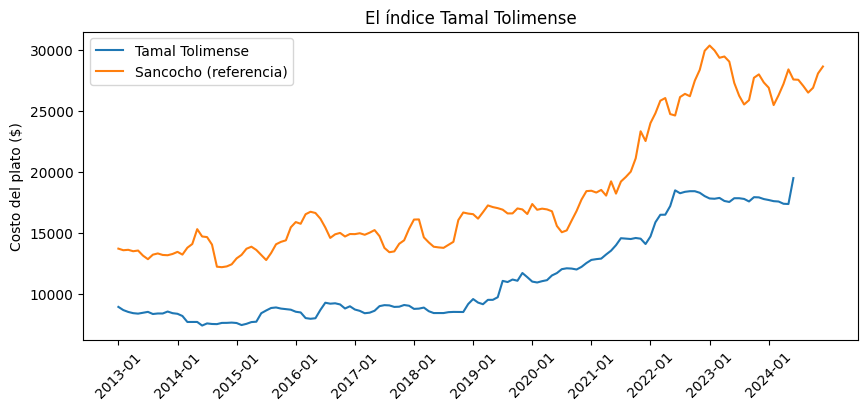

In [171]:
# ✏️ Ejercicio 4 — Su plato, su índice.
RECETA_PROPIA = RECETA2
print("Ingredientes:", len(RECETA1), "| Kilos totales:", sum(RECETA1.values()))
    # "Producto oficial del DANE": kilos,
NOMBRE_PLATO = "Tamal Tolimense"
CIUDAD_PROPIA = "Manizales"

if RECETA_PROPIA:
    mi_indice = indice_plato(df_filtrado, CIUDAD_PROPIA, RECETA_PROPIA)
    plt.figure(figsize=(10, 4))
    plt.plot(range(len(mi_indice)), mi_indice.values, label=NOMBRE_PLATO)
    plt.plot(range(len(sancocho_mzl)), sancocho_mzl.values, label="Sancocho (referencia)")
    plt.xticks(range(0, len(sancocho_mzl), 12), sancocho_mzl.index[::12], rotation=45)
    plt.ylabel("Costo del plato ($)")
    plt.legend()
    plt.title(f"El índice {NOMBRE_PLATO}")
    plt.show()
    # ¿Su plato se infló más o menos que el sancocho? ¿En qué años se separan las curvas?

---
## 6 · Momento 3 — Explicar + la cacería estrella

🗣️ Una página del equipo: (1) la apuesta de conmutatividad — qué apostaron, qué dio el juez, y la moraleja con la propiedad nombrada; (2) la clasificación de invertibilidad de su pipeline (¿qué pasos tienen camino de regreso?); (3) la lectura histórica de sus dos picos; (4) el veredicto del duelo de ciudades con su tabla de equivalencias defendida.

🤖 **Y el cierre de la cacería estrella:** en la sesión 1 le preguntaron a su IA cuánto cuesta un sancocho para seis. Peguen aquí su respuesta de entonces y el número de SU índice para el mes actual del congelado. ¿Quién tenía la cifra y quién tenía el cuento? Al expediente (bitácora individual) — esta comparación es la demostración empírica de la regla del curso: *la IA no es la autoridad final; los datos, sí.*

**Entregables:** cuaderno ejecutado completo + bitácora individual + tarea puente (verificación reproducida y defensa del precio medio). Rúbrica en la guía. Cuaderno que no ejecuta: se devuelve sin calificar.